In [ ]:
import torch
import torchvision

import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

Нормализация данных


In [76]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

Загрузка датасета

In [77]:
 train_dataset = torchvision.datasets.CIFAR10(
    root = "./data", train = True, download = True, transform = train_transform
)

In [78]:
test_dataset = torchvision.datasets.CIFAR10(
    root = "./data", train = False, download = True, transform = test_transform
)

In [79]:
train_loader = DataLoader(
    train_dataset, batch_size = 128, shuffle = True, num_workers = 2
)

In [80]:
test_loader = DataLoader(
    test_dataset, batch_size = 128, shuffle = False, num_workers = 2
)

Проверка


In [81]:
def imshow(img):
    mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

    img = img * std + mean
    img = torch.clamp(img, 0, 1)

    plt.imshow(img.permute(1, 2, 0))
    plt.axis("off")

Train size: 50000
Test size: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of classes: 10
Image shape: torch.Size([3, 32, 32])
Label: 6
Batch images shape: torch.Size([128, 3, 32, 32])
Batch labels shape: torch.Size([128])


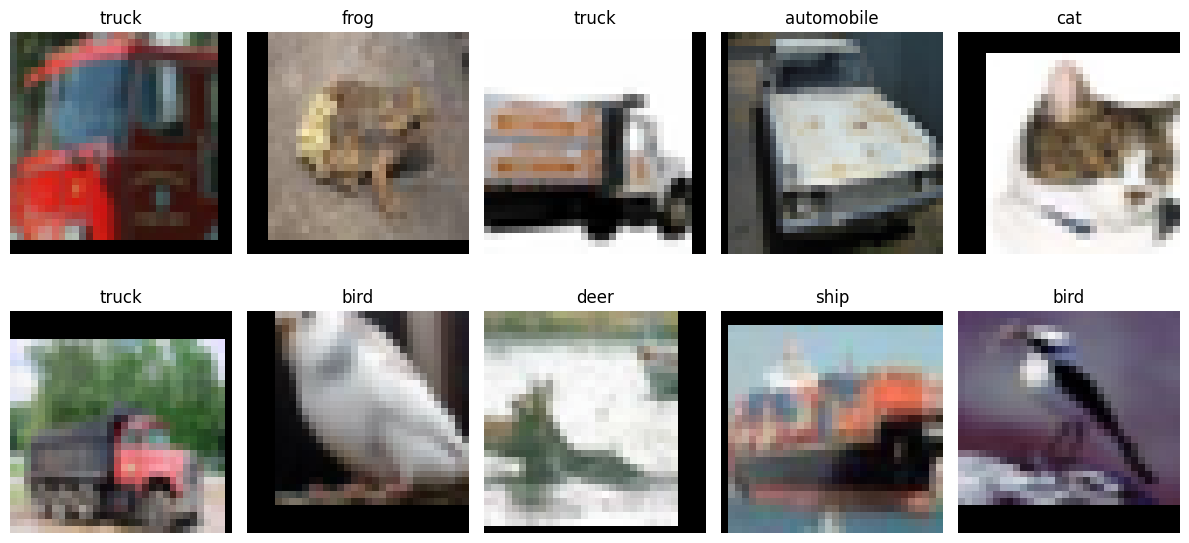

In [82]:
images, labels = next(iter(train_loader))

print("Train size:", len(train_dataset))
print("Test size:", len(test_dataset))

print("Classes:", train_dataset.classes)
print("Number of classes:", len(train_dataset.classes))

print("Image shape:", train_dataset[0][0].shape)
print("Label:", train_dataset[0][1])

print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)

def show_images(images, labels):
    fig, axes = plt.subplots(2, 5, figsize=(12, 6))

    for i, ax in enumerate(axes.flat):
        img = images[i]

        mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
        std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

        img = img * std + mean
        img = torch.clamp(img, 0, 1)

        img = img.permute(1, 2, 0)

        ax.imshow(img)
        ax.set_title(train_dataset.classes[labels[i].item()])
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_images(images, labels)

In [83]:
import torch.nn as nn
import torch.nn.functional as F

In [84]:
from torch.nn.modules.flatten import Flatten
from torch.nn.modules.pooling import MaxPool2d

class CNN(nn.Module):
  def __init__(self, num_classes = 10):
    super().__init__()
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(
            in_channels = 3,
            out_channels = 64,
            kernel_size = 3,
            padding = 1
        ),
        nn.BatchNorm2d(64),
        nn.ReLU(),

        nn.Conv2d(
            in_channels = 64,
            out_channels = 64,
            kernel_size = 3,
            padding = 1
        ),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)
    )

    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(
            in_channels = 64,
            out_channels = 128,
            kernel_size = 3,
            padding = 1
        ),
        nn.BatchNorm2d(128),
        nn.ReLU(),

        nn.Conv2d(
            in_channels = 128,
            out_channels = 128,
            kernel_size = 3,
            padding = 1
        ),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)
    )

    self.conv_block_3 = nn.Sequential(
        nn.Conv2d(
            in_channels = 128,
            out_channels = 256,
            kernel_size = 3,
            padding = 1
        ),
        nn.BatchNorm2d(256),
        nn.ReLU(),

        nn.Conv2d(
            in_channels = 256,
            out_channels = 256,
            kernel_size = 3,
            padding = 1
        ),
        nn.BatchNorm2d(256),
        nn.ReLU(),

    )

    self.adapt_avg_pool = nn.AdaptiveAvgPool2d(1)
    self.dropout = nn.Dropout(0.5)
    self.classifier = nn.Linear(256, num_classes)

  def forward(self, x):
    x = self.conv_block_1(x)
    x = self.conv_block_2(x)
    x = self.conv_block_3(x)
    x = self.adapt_avg_pool(x)
    x = torch.flatten(x, 1)
    x = self.dropout(x)
    x = self.classifier(x)

    return x

Проверка


In [85]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


Создание модели

In [94]:
model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=0.00001)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, 25)


Подсчет обучаемых параметров


In [93]:
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {total_params:,}")



Trainable parameters: 1,149,770


Цикл обучения

In [87]:
def evaluate(model, loader, criterion, device):
    model.eval()

    correct = 0
    total = 0
    running_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            predicted = outputs.argmax(dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            running_loss += loss.item() * labels.size(0)

    accuracy = 100 * correct / total
    error = 100 - accuracy
    avg_loss = running_loss / total

    return accuracy, error, avg_loss

In [95]:
NUM_EPOCHS = 25
train_losses = []
test_losses = []

train_accuracies = []
test_accuracies = []

for epoch in range(NUM_EPOCHS):
  model.train()
  correct = 0
  total = 0
  running_loss = 0.0

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)

    loss = criterion(outputs, labels)
    loss.backward()

    running_loss += loss.item()
    optimizer.step()

    predicted = outputs.argmax(dim=1)

    correct += (predicted == labels).sum().item()
    total += labels.size(0)

  accuracy = 100 * correct / total
  error = 100 - accuracy
  epoch_loss = running_loss / len(train_loader)
  scheduler.step()
  print(
    f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
    f"Accuracy: {accuracy:.2f}% "
    f"Error: {error:.2f}%"
  )
  test_accuracy, test_error, test_loss = evaluate(
    model, test_loader, criterion, device
  )
  print(f"Loss: {epoch_loss:.4f}")


  print(
    f"Test Accuracy: {test_accuracy:.2f}% "
    f"Error: {test_error:.2f}% "
    f"Loss: {test_loss:.4f}"
  )
  train_losses.append(epoch_loss)
  test_losses.append(test_loss)

  train_accuracies.append(accuracy)
  test_accuracies.append(test_accuracy)

Epoch [1/25] Accuracy: 44.46% Error: 55.54%
Loss: 1.5116
Test Accuracy: 54.40% Error: 45.60% Loss: 1.3253
Epoch [2/25] Accuracy: 63.08% Error: 36.92%
Loss: 1.0361
Test Accuracy: 55.24% Error: 44.76% Loss: 1.4096
Epoch [3/25] Accuracy: 69.79% Error: 30.21%
Loss: 0.8570
Test Accuracy: 68.97% Error: 31.03% Loss: 0.8813
Epoch [4/25] Accuracy: 75.00% Error: 25.00%
Loss: 0.7270
Test Accuracy: 76.60% Error: 23.40% Loss: 0.6908
Epoch [5/25] Accuracy: 77.96% Error: 22.04%
Loss: 0.6350
Test Accuracy: 77.95% Error: 22.05% Loss: 0.6590
Epoch [6/25] Accuracy: 80.44% Error: 19.56%
Loss: 0.5698
Test Accuracy: 75.55% Error: 24.45% Loss: 0.7390
Epoch [7/25] Accuracy: 82.39% Error: 17.61%
Loss: 0.5141
Test Accuracy: 80.93% Error: 19.07% Loss: 0.5948
Epoch [8/25] Accuracy: 83.91% Error: 16.09%
Loss: 0.4725
Test Accuracy: 82.28% Error: 17.72% Loss: 0.5589
Epoch [9/25] Accuracy: 85.25% Error: 14.75%
Loss: 0.4341
Test Accuracy: 81.66% Error: 18.34% Loss: 0.5908
Epoch [10/25] Accuracy: 86.40% Error: 13.60%
L

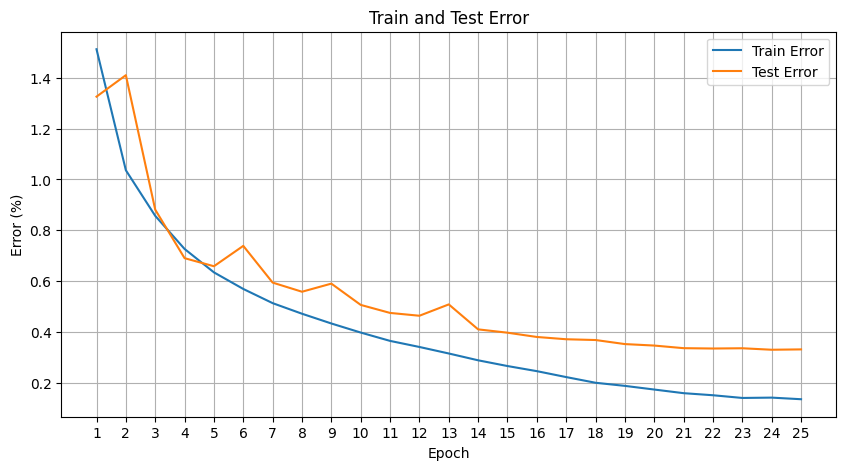

In [96]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs, train_losses, label="Train Error")
plt.plot(epochs, test_losses, label="Test Error")

plt.xlabel("Epoch")
plt.ylabel("Error (%)")
plt.title("Train and Test Error")
plt.xticks(epochs)
plt.legend()
plt.grid()

plt.show()

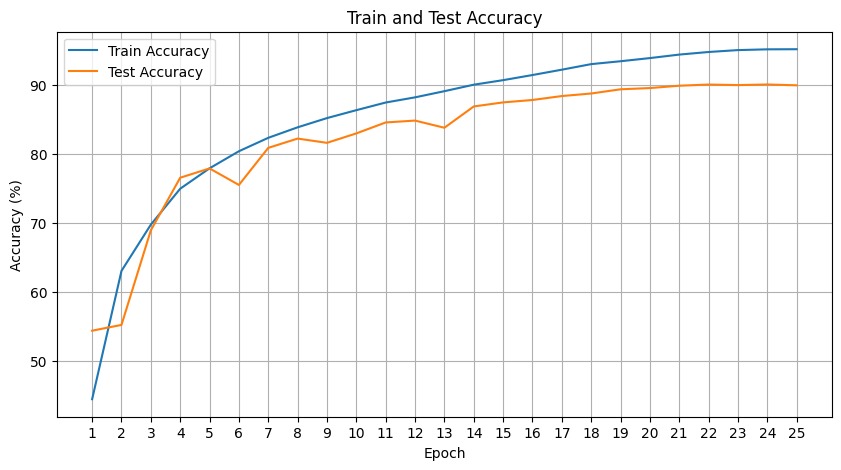

In [97]:
plt.figure(figsize=(10, 5))

plt.plot(epochs, train_accuracies, label="Train Accuracy")
plt.plot(epochs, test_accuracies, label="Test Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Train and Test Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid()

plt.show()